In [1]:
'''
Confidence interval in forecasts

Change points 

Sarimax - will be explained in the next chapter in detail
'''

'\nConfidence interval in forecasts\n\nChange points \n\nSarimax - will be explained in the next chapter in detail\n'

# Pre processing

In [11]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
import ruptures as rpt

In [3]:
df=pd.read_csv(r'C:\Users\Mayank Bhatia\Documents\GitHub\DSML\16_ml_unsupervised_and_recsys\16.5_time_seties_analysis_4\mobilesales.csv')

In [4]:
df['DATE']=pd.to_datetime(df['DATE'],format=('%d-%m-%Y'))
df.set_index('DATE',inplace=True)

In [5]:
df['Sales_2']=df['Sales'].interpolate(method='linear')
df['Sales_3']=df['Sales_2'].clip(lower=np.quantile(df['Sales_2'],0.05),upper=np.quantile(df['Sales_2'],0.95))

In [6]:
df_train=df[:-12]
df_test=df[-12:]

# confidence interval using SARIMAX

In [7]:
model=SARIMAX(df_train['Sales_3'],order=(3,1,3),seasonal_order=(1,1,1,12))
model=model.fit()

c:\Users\Mayank Bhatia\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Mayank Bhatia\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Mayank Bhatia\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [8]:
df_test['pred']=model.forecast(steps=12)
df_test['lower'],df_test['upper']=model.get_forecast(steps=12).conf_int(0.05).values.T



# model.get_forecast(steps=12).conf_int(0.05)

In [9]:
df_test

,Sales,Sales_2,Sales_3,pred,lower,upper
DATE,,,,,,
2018-02-01,11852.0,11852.0,11852.0,12182.617752,10711.672816,13653.562688
2018-03-01,14123.0,14123.0,14123.0,13961.930600,12439.664817,15484.196383
2018-04-01,13360.0,13360.0,13360.0,13985.551368,12456.700722,15514.402014
2018-05-01,15576.0,15576.0,15164.6,14880.583464,13341.217748,16419.949180
2018-06-01,16021.0,16021.0,15164.6,15302.790446,13723.513528,16882.067365
2018-07-01,14080.0,14080.0,14080.0,13995.723286,12414.072307,15577.374264
2018-08-01,15697.0,15697.0,15164.6,14060.300665,12450.892003,15669.709328
2018-09-01,13838.0,13838.0,13838.0,13773.338539,12146.040852,15400.636226
2018-10-01,15351.0,15351.0,15164.6,14354.993287,12721.931770,15988.054805


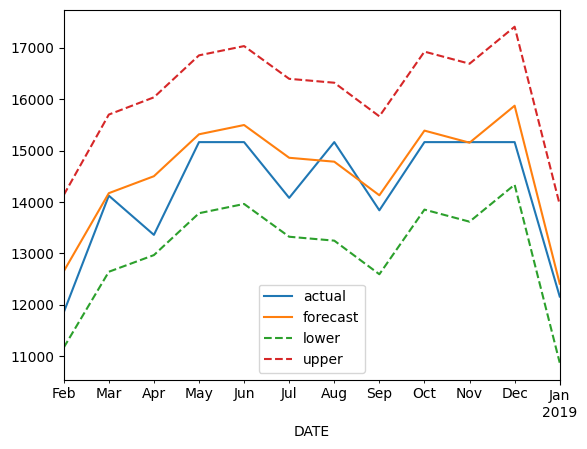

In [20]:
df_test['Sales_3'].plot(label='actual')
df_test['pred'].plot(label='forecast')
df_test['lower'].plot(label='lower',style='--')
df_test['upper'].plot(label='upper',style='--')

plt.legend()


# Change point using ruptures

In [13]:
model=rpt.Pelt(model='rbf').fit(df['Sales_3'].values)

In [14]:
result=model.predict(pen=10)